# Benchmark: unordered and ordered categorical responses

Two simulated classification tasks with 1,500 training and 5,000 test rows
and six predictors, three of which matter:

* **multiclass**: three unordered classes, with log-odds against class 0 of
  $\sin 2x_1 + 0.5x_3$ for class 1 and $0.8x_2 - 0.8(x_3^2 - 1/3)$ for class 2;
* **ordinal**: four ordered classes cut at $-1$, $0$ and $1$ from a latent
  score $\sin 1.5x_1 + 0.6x_2 + 0.5[x_3 > 0]$ plus logistic noise, which is a
  proportional-odds model.

mboostrs fits `Multinomial` on both tasks and `PropOdds` (the
proportional-odds, or cumulative logit, model) on the ordinal one. The
competitors are mgcv's multinomial GAM (`multinom`) and ordered-categorical
GAM (`ocat`), statsmodels' linear proportional-odds model, scikit-learn's
multinomial logistic regression, EBM, APLR, XGBoost, LightGBM and CatBoost.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | predicted class probabilities and the recovered effect of each predictor on the log-odds |
| **Observed response** | a simulated class label, unordered or ordered |
| **Estimand** | test log-loss (mean negative log-probability of the observed class), accuracy, and the error of the partial dependence of $\log(p_k/p_0)$ (multiclass) or $\operatorname{logit} P(y \ge 2)$ (ordinal) against the true centred effect |
| **Units** | nats per row; proportion; log-odds |
| **Sampling unit** | one row; 1,500 training and 5,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | a fresh test sample from the same design |
| **Tuning** | mboostrs: `tune_mstop` (5-fold CV); trees: early stopping on a 20% validation split over a size grid; mgcv: REML; EBM, APLR, logistic regression, statsmodels: defaults |
| **Uncertainty** | mean and standard error over 8 seeds |
| **Claim type** | methodological |
:::

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_classes.json").read_text())
failed = [r for r in bench["results"] if "error" in r]
classes = pl.from_dicts([r for r in bench["results"] if "error" not in r],
                        infer_schema_length=None, strict=False)
table = (classes.group_by("task", "method")
         .agg(pl.col("log_loss").mean(),
              (pl.col("log_loss").std() / pl.len().sqrt()).alias("log_loss se"),
              pl.col("accuracy").mean(), pl.col("effect_rmse").mean(), pl.col("seconds").mean())
         .sort("task", "log_loss"))


def value(task, method, column):
    return float(table.filter((pl.col("task") == task) & (pl.col("method") == method))[column][0])


f"{classes.height} fits; {len(failed)} failed"

'160 fits; 0 failed'

In [2]:
from bench_tables import table as annotated

# One row per method, the two tasks side by side.
def task_columns(task, prefix):
    return table.filter(pl.col("task") == task).select(
        "method", *[pl.col(c).alias(f"{prefix}_{c}")
                    for c in ("log_loss", "log_loss se", "accuracy", "effect_rmse")])


wide = (task_columns("multiclass", "mc")
        .join(task_columns("ordinal", "or"), on="method", how="full", coalesce=True)
        .join(table.group_by("method").agg(pl.col("seconds").mean()), on="method")
        .sort("mc_log_loss", nulls_last=True))
annotated(
    wide,
    title="Categorical responses: every method on both tasks",
    subtitle="Mean over 8 simulated draws; 1,500 training and 5,000 test rows per draw",
    spanners={"Three unordered classes": ["mc_log_loss", "mc_log_loss se", "mc_accuracy", "mc_effect_rmse"],
              "Four ordered classes": ["or_log_loss", "or_log_loss se", "or_accuracy", "or_effect_rmse"]},
    labels={"mc_log_loss": "log-loss ↓", "mc_log_loss se": "se", "mc_accuracy": "accuracy ↑",
            "mc_effect_rmse": "effect ↓", "or_log_loss": "log-loss ↓", "or_log_loss se": "se",
            "or_accuracy": "accuracy ↑", "or_effect_rmse": "effect ↓", "seconds": "s"},
    better={"mc_log_loss": "min", "or_log_loss": "min", "mc_accuracy": "max", "or_accuracy": "max",
            "mc_effect_rmse": "min", "or_effect_rmse": "min"},
    decimals=4, formats={"mc_effect_rmse": 3, "or_effect_rmse": 3, "seconds": 1},
    notes=["log-loss: mean negative log-probability of the observed class on the test rows, in "
           "nats; se is its standard error over the 8 draws. accuracy: share of test rows whose "
           "most probable class is the observed one.",
           "effect: root mean squared difference between each true predictor's estimated partial "
           "effect and its true centred effect, on log(p_k/p_0) for the unordered task and on "
           "logit P(y ≥ 2) for the ordered one. – : the method gives no partial effect or does not "
           "fit that task. s: mean seconds per fit, including tuning.",
           "Bold: best in the column. Rows are sorted by the unordered log-loss. The leading "
           "log-losses differ by less than two standard errors. Source: bench_classes.json, "
           "written by benches/bench_classes.py."])


GT(_tbl_data=shape: (13, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ method    ┆ mc_log_lo ┆ mc_log_lo ┆ mc_accura ┆ … ┆ or_log_lo ┆ or_accura ┆ or_effect ┆ seconds  │
│ ---       ┆ ss        ┆ ss se     ┆ cy        ┆   ┆ ss se     ┆ cy        ┆ _rmse     ┆ ---      │
│ str       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ f64      │
│           ┆ f64       ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ mboostrs  ┆ 1.010263  ┆ 0.001842  ┆ 0.5009    ┆ … ┆ null      ┆ null      ┆ null      ┆ 4.019473 │
│ autospec  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ mboostrs  ┆ 1.010315  ┆ 0.001839  ┆ 0.500725  ┆ … ┆ null      ┆ null      ┆ null      ┆ 10.48775 │
│ Multinomi ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ al,       ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ linear +… ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ mgcv      ┆ 1.010505  ┆ 0.002697  ┆ 0.499675  ┆ … ┆ null      ┆ null      ┆ null      ┆ 23.57169 │
│ multinom  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 3        │
│ EBM       ┆ 1.01241   ┆ 0.001697  ┆ 0.495     ┆ … ┆ 0.002875  ┆ 0.42385   ┆ 0.080547  ┆ 30.85125 │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 7        │
│ logistic  ┆ 1.013815  ┆ 0.002005  ┆ 0.49635   ┆ … ┆ 0.002403  ┆ 0.424075  ┆ 0.078802  ┆ 1.31312  │
│ regressio ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n         ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ …         ┆ …         ┆ …         ┆ …         ┆ … ┆ …         ┆ …         ┆ …         ┆ …        │
│ CatBoost  ┆ 1.018838  ┆ 0.002036  ┆ 0.49105   ┆ … ┆ 0.002648  ┆ 0.4183    ┆ 0.095383  ┆ 3.025036 │
│ mboostrs  ┆ 1.021709  ┆ 0.001333  ┆ 0.488125  ┆ … ┆ 0.00281   ┆ 0.417775  ┆ 0.117217  ┆ 15.12006 │
│ Multinomi ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 3        │
│ al        ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ statsmode ┆ null      ┆ null      ┆ null      ┆ … ┆ 0.002257  ┆ 0.42515   ┆ 0.068054  ┆ 1.425048 │
│ ls propor ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ tional    ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ odds …    ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ mgcv ocat ┆ null      ┆ null      ┆ null      ┆ … ┆ 0.002572  ┆ 0.4244    ┆ 0.070374  ┆ 9.46439  │
│ mboostrs  ┆ null      ┆ null      ┆ null      ┆ … ┆ 0.002431  ┆ 0.4259    ┆ 0.059581  ┆ 8.501128 │
│ PropOdds  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x11322be90>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='mc_log_loss', type=<ColInfoTypeEnum.default: 1>, column_label='log-loss ↓', column_align='right', column_width=None), ColInfo(var='mc_log_loss se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='mc_accuracy', type=<ColInfoTypeEnum.default: 1>, column_label='accuracy ↑', column_align='right', column_width=None), ColInfo(var='mc_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='effect ↓', column_align='right', column_width=None), ColInfo(var='or_log_loss

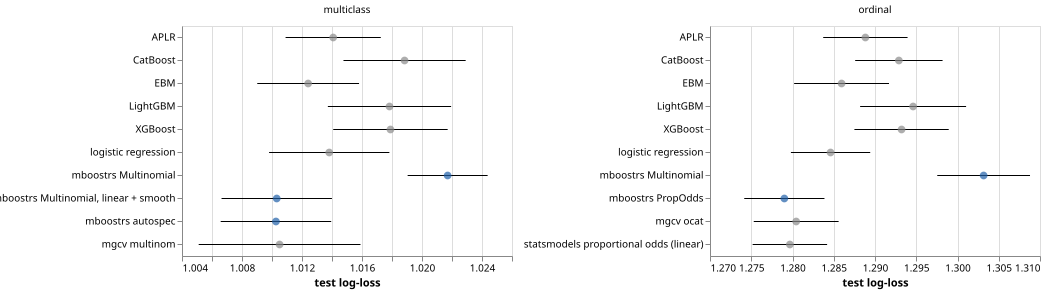

In [3]:
data = table.with_columns(
    (pl.col("log_loss") - 2 * pl.col("log_loss se")).alias("low"),
    (pl.col("log_loss") + 2 * pl.col("log_loss se")).alias("high"),
    pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
base = alt.Chart(data).encode(y=alt.Y("method:N", sort="x", title=None))
display((base.mark_rule().encode(x=alt.X("low:Q", title="test log-loss", scale=alt.Scale(zero=False)),
                                 x2="high:Q")
         + base.mark_point(filled=True, size=60).encode(
             x="log_loss:Q", color=alt.Color("mboostrs:N", legend=None,
                                             scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"]))))
        .properties(width=330, height=230)
        .facet(column=alt.Column("task:N", title=None))
        .resolve_scale(x="independent", y="independent"))

## Unordered classes

The best log-losses are within a few thousandths of each other. mboostrs'
`Multinomial` with each predictor written as a linear term plus a centred
smooth deviation with one degree of freedom,
`bols(x) + bbs(x, center=TRUE, df=1)` (so that a linear term and a centred smooth deviation compete on equal terms), has the lowest,
{eval}`round(value("multiclass", "mboostrs Multinomial, linear + smooth", "log_loss"), 4)`,
and the smallest effect error,
{eval}`round(value("multiclass", "mboostrs Multinomial, linear + smooth", "effect_rmse"), 3)`;
mgcv's multinomial GAM follows at
{eval}`round(value("multiclass", "mgcv multinom", "log_loss"), 4)`, then EBM
({eval}`round(value("multiclass", "EBM", "log_loss"), 4)`) and linear logistic
regression ({eval}`round(value("multiclass", "logistic regression", "log_loss"), 4)`).
Half of the true effects are linear and the rest are gentle curves.
`autospec`, which proposes this decomposition for a Multinomial response and
tunes it, reaches
{eval}`round(value("multiclass", "mboostrs autospec", "log_loss"), 4)`.
`Multinomial` with a `bbs(x, df=4)` term per predictor is last
({eval}`round(value("multiclass", "mboostrs Multinomial", "log_loss"), 4)`); the R package mboost (model-based boosting, which mboostrs follows), fitted to the same data with the same terms, reaches the same value
(1.023 at its best step count on one seed, against 1.022 here). With `df=4`
every step fits a four-degree-of-freedom curve even where a straight line
suffices.


## Ordered classes

mboostrs' `PropOdds` has the lowest log-loss,
{eval}`round(value("ordinal", "mboostrs PropOdds", "log_loss"), 4)`, and the
smallest effect error, {eval}`round(value("ordinal", "mboostrs PropOdds", "effect_rmse"), 3)`,
ahead of statsmodels' linear proportional-odds model
({eval}`round(value("ordinal", "statsmodels proportional odds (linear)", "log_loss"), 4)`)
and mgcv's `ocat` ({eval}`round(value("ordinal", "mgcv ocat", "log_loss"), 4)`).
Treating the classes as unordered costs accuracy: every multiclass method is
behind the three ordinal ones, and mboostrs' own `Multinomial` on this task
reaches {eval}`round(value("ordinal", "mboostrs Multinomial", "log_loss"), 4)`.
It takes {eval}`round(value("ordinal", "mboostrs PropOdds", "seconds"), 1)`
seconds per fit with tuning, about as long as mgcv
({eval}`round(value("ordinal", "mgcv ocat", "seconds"), 1)`), because every
boosting step re-estimates the three thresholds; the linear statsmodels model
takes {eval}`round(value("ordinal", "statsmodels proportional odds (linear)", "seconds"), 1)`.

## Behaviour of the ordinal and multinomial fits

* **Threshold parameterization in `PropOdds`.** The thresholds are parameterized as in R's mboost, $\sigma = \delta_1 + \operatorname{cumsum}(0, e^{\delta_2}, e^{\delta_3}, \dots)$, which keeps them increasing. A four-level linear fit matches mboost's thresholds and coefficients to $3 \times 10^{-4}$.
* **Held-out scoring in `Multinomial` cross-validation.** mboost's multinomial loss leaves the reference class (the baseline category; class 0 here) out of the negative log-likelihood. `cvrisk`, the function that estimates held-out risk at every step count, scores held-out rows with the full negative log-likelihood, which includes the reference class term and so measures the fit of all the predicted probabilities. The in-bag risk path matches mboost. This differs from mboost's `cvrisk` by design.
* **Speed of the `PropOdds` threshold search.** The search evaluates the risk about 30 times per threshold at each step. Each row reads its two neighbouring thresholds from precomputed exponentials, so the exponentials are not recomputed in each evaluation. The results are unchanged.
* **Input levels for `PropOdds`.** `PropOdds` accepts `levels=[...]`, for example `levels=["low", "mid", "high"]` or `levels=[0, 1, 2]` for zero-based codes, and it reads the declared order of a pandas ordered `Categorical` or a polars `Enum`.
* **Centred terms in `Multinomial`.** In a `Multinomial` model, `bbs(x, center=TRUE)` is fitted on the deviation from the linear term, in Python and R. `autospec` proposes the linear-plus-smooth decomposition for a Multinomial response.


## Summary

| Task | Leader | mboostrs |
|---|---|---|
| Unordered classes | mboostrs `bols + bbs(center, df=1)`, mgcv multinom | lowest log-loss and effect error with the decomposition; with `bbs(df=4)`, last |
| Ordered classes | mboostrs `PropOdds` | best log-loss and effect recovery; as fast as mgcv |

The leading log-loss values are close: the linear-plus-smooth mboostrs
model, mgcv and EBM differ by only a few thousandths for unordered classes;
`PropOdds` and mgcv `ocat` differ by about one thousandth for ordered
classes. Eight simulated seeds do not establish a general ranking from
these small gaps.

## Limitations

Both tasks are additive with gentle effects, which favours the additive and
linear methods; a design with interactions between predictors would favour
the tree methods. The comparison with R's mboost on the multiclass task uses
one seed. The results are in `docs/book/cases/bench_classes.json`, produced
by `benches/bench_classes.py`.